[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-2/blob/main/notebooks/ch36_LabCh36_Decoding_Methods.ipynb)

**The Why Book of Deep Learning, Part 2** by Dr. Philemon Paul Daniel

**Chapter 36: Generating Text: Every Decoding Method, and When** (Part VIII: Language Models).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-2/read.html?ch=36](https://www.micyaai.com/books/why-deep-learning-2/read.html?ch=36)
* Part 1 of the book and its notebooks: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)
* The simplified video course for kids: [aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-2](https://github.com/phildani7/why-book-of-deep-learning-part-2)

Tested with TensorFlow 2.21 and Keras 3.14 on a laptop CPU (about five minutes or less). In Colab:
*Runtime > Run all*. It runs on the free CPU runtime; a GPU runtime works too and is usually faster, but the
printed timings and some last digits will differ from the saved outputs.

---


# Lab Ch36 - Decoding Methods
## One model, one probability table, and a dozen ways to pick from it

This lab goes with **Chapter 36** of *The Why Book of Deep Learning, Part 2*.

A language model does not write. It hands you a table of probabilities for the next token. A separate rule,
the **decoder**, picks one token from that table, appends it, and asks again. In this lab you train TinyGPT
(the model of Chapter 35), then write every common decoding rule by hand in NumPy on its logits: greedy,
pure sampling, temperature, top-k, top-p, min-p, repetition penalties, n-gram blocking, beam search,
stopping rules, logit bias and a grammar mask. You then measure what each one does to the same model, and
finish by building a KV cache and timing it.

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Read a next-token table: its peak, its entropy, its tail | Steps 5 and 7 |
| Write the generation loop and explain why greedy decoding loops | Step 6 |
| Apply temperature, top-k, top-p and min-p to logits, in the right order | Steps 8 to 12 |
| Say what a repetition penalty breaks | Step 13 |
| Write beam search and say why its "best" text is not good text | Step 14 |
| Measure decoders: log-probability, repetition, variety | Step 15 |
| Stop a model, bias a token, and force an output to fit a grammar | Steps 16 and 17 |
| Classify with a generative model without sampling | Step 17 |
| Build a KV cache, prove it changes nothing, and count what it saves | Steps 18 and 19 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**.

> **Runtime:** three to four minutes on a laptop CPU. Step 4 (training) takes about two of them. No GPU is
> needed. The only download is the IMDB data set that ships with Keras.

> **Honest scale, twice over.** (1) TinyGPT here is trained for 2,000 steps, a shorter run than Chapter 35's
> 3,000, so that the experiments fit in the time. It spells; it does not know anything. (2) Its vocabulary is
> **39 characters**, not 50,000 subword tokens. Top-k and top-p were invented for tables with tens of
> thousands of entries and a long tail. On 39 entries the tail is short, so this lab uses small values
> (k = 3 or 5) to make the effects visible, and Step 7 builds a 50,000-entry table by hand to show the
> full-size picture. Numbers printed here describe this miniature, not any large model.

---
## Step 1 - Imports and one seed

In [1]:
import os, time
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 36
keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)
np.set_printoptions(precision=3, suppress=True)
t_start = time.time()
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.14.1


---
## Step 2 - The corpus and the tokenizer (copied from Chapter 35)

The same 3,000 IMDB reviews, decoded back to lowercase text, and the same tokenizer: one character, one id,
39 characters in all. Id 0 is the newline that ends every review. Remember that: it is the only way this
model has of saying "I have finished" (Step 16).

> **Predict:** in this lab a *token* is one character. Roughly how many tokens is the phrase
> `this movie was`? How many would it be for a subword tokenizer (Chapter 33)?

In [2]:
ALPHABET = "\n '0123456789abcdefghijklmnopqrstuvwxyz"   # newline, space, apostrophe, digits, letters


def load_corpus(n_reviews=3000):
    """IMDB reviews from keras.datasets, decoded to lowercase text. Returns a list of strings, one per review.
    Only the characters in ALPHABET survive; everything else is dropped."""
    (x_train, _), _ = keras.datasets.imdb.load_data()
    word_index = keras.datasets.imdb.get_word_index()
    id_to_word = {i + 3: w for w, i in word_index.items()}      # ids 0, 1, 2 are pad, start, unknown
    keep = set(ALPHABET) - {"\n"}
    reviews = []
    for ids in x_train[:n_reviews]:
        words = [id_to_word.get(i, "") for i in ids if i >= 3]
        line = " ".join(w for w in words if w and w != "br").lower()
        line = "".join(ch for ch in line if ch in keep)
        reviews.append(" ".join(line.split()))
    return reviews


V = len(ALPHABET)
char_to_id = {ch: i for i, ch in enumerate(ALPHABET)}


def encode(text):
    """text -> array of ids. Characters outside ALPHABET are dropped."""
    return np.array([char_to_id[ch] for ch in text.lower() if ch in char_to_id], dtype=np.int32)


def decode(ids):
    """ids -> text."""
    return "".join(ALPHABET[int(i)] for i in ids)


reviews = load_corpus()
n_train_reviews = int(len(reviews) * 0.9)
train_ids = encode("\n".join(reviews[:n_train_reviews]) + "\n")
val_ids = encode("\n".join(reviews[n_train_reviews:]) + "\n")
real_words = set(w for r in reviews[:n_train_reviews] for w in r.split())      # used in Step 15
print(f"V = {V} | train: {len(train_ids):,} characters | validation: {len(val_ids):,} characters")
print(f"'this movie was' is {len(encode('this movie was'))} tokens here")
print(f"newline is id {char_to_id[chr(10)]}; it appears once per review: {int((train_ids == 0).sum()):,} times in training,")
print(f"   one character in every {len(train_ids) / (train_ids == 0).sum():,.0f}")

V = 39 | train: 3,500,601 characters | validation: 393,306 characters
'this movie was' is 14 tokens here
newline is id 0; it appears once per review: 2,700 times in training,
   one character in every 1,297


---
## Step 3 - Build TinyGPT (copied from Chapter 35)

Decoder-only, pre-norm, width 64, 4 heads, 2 blocks, feed-forward 256, context 64, learnt positions, untied
head. The functions are Chapter 35's, word for word, so the two labs build the same model.

> **Predict:** the parameter count. (Chapter 35's formula: tables V·d + T·d, each block 49,984, final norm
> 2d, head d·V + V.)

In [3]:
CONTEXT = 64


def random_windows(data, n, context=CONTEXT, rng=rng):
    """n windows starting at random places in data. Returns x (n, context) and y (n, context), y = x shifted by one."""
    starts = rng.integers(0, len(data) - context - 1, size=n)
    idx = starts[:, None] + np.arange(context + 1)[None, :]
    w = data[idx]
    return w[:, :-1], w[:, 1:]


class TokenAndPosition(layers.Layer):
    """ids (batch, T) -> vectors (batch, T, d): a token table plus a learnt position table."""

    def __init__(self, vocab_size, context, d, **kwargs):
        super().__init__(**kwargs)
        init = keras.initializers.RandomNormal(stddev=0.02)
        self.token_table = layers.Embedding(vocab_size, d, embeddings_initializer=init, name="token_table")
        self.position_table = layers.Embedding(context, d, embeddings_initializer=init, name="position_table")

    def call(self, ids):
        positions = keras.ops.arange(keras.ops.shape(ids)[1])
        return self.token_table(ids) + self.position_table(positions)


def build_tinygpt(vocab_size, d=64, heads=4, blocks=2, ff=256, context=64, dropout=0.0, causal=True):
    """TinyGPT: decoder-only, pre-norm, learnt positions, untied head. ids (batch, context) -> logits (batch, context, vocab_size).
    causal=False removes the mask (only to show what goes wrong). Needs the TokenAndPosition layer above."""
    ids = layers.Input(shape=(context,), dtype="int32", name="ids")
    x = TokenAndPosition(vocab_size, context, d, name="embed")(ids)
    for b in range(1, blocks + 1):
        h = layers.LayerNormalization(epsilon=1e-5, name=f"block{b}_norm1")(x)
        h = layers.MultiHeadAttention(num_heads=heads, key_dim=d // heads, dropout=dropout,
                                      name=f"block{b}_attention")(h, h, use_causal_mask=causal)
        x = layers.Add(name=f"block{b}_add1")([x, h])
        h = layers.LayerNormalization(epsilon=1e-5, name=f"block{b}_norm2")(x)
        h = layers.Dense(ff, activation="gelu", name=f"block{b}_ff_wide")(h)
        h = layers.Dense(d, name=f"block{b}_ff_narrow")(h)
        if dropout > 0:
            h = layers.Dropout(dropout, name=f"block{b}_dropout")(h)
        x = layers.Add(name=f"block{b}_add2")([x, h])
    x = layers.LayerNormalization(epsilon=1e-5, name="final_norm")(x)
    logits = layers.Dense(vocab_size, kernel_initializer=keras.initializers.RandomNormal(stddev=0.02), name="head")(x)
    return keras.Model(ids, logits, name="TinyGPT")


model = build_tinygpt(V)
hand_count = V * 64 + 64 * 64 + 2 * 49_984 + 2 * 64 + (64 * V + V)
print("Keras count:", f"{model.count_params():,}", "| hand count:", f"{hand_count:,}")
assert model.count_params() == hand_count == 109_223

Keras count: 109,223 | hand count: 109,223


---
## Step 4 - Train it: a shorter run than Chapter 35's

Chapter 35 trained for 3,000 steps. Here we stop at **2,000** (batch 64, the same AdamW, warm-up and cosine
recipe) to leave time for the experiments. The model will be a little worse than Chapter 35's. That does not
matter for this lab: every decoder below works on whatever table the model gives.

> **Predict:** Chapter 35 reached a validation loss of 1.470 after 3,000 steps. Will 2,000 steps land above
> or below 1.5?

> This is the slow cell: about two minutes on a laptop CPU.

In [4]:
BATCH, STEPS, PEAK_LR = 64, 2000, 3e-3
loss_fn = keras.losses.SparseCategoricalCrossentropy(from_logits=True)
schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=0.0, warmup_target=PEAK_LR, warmup_steps=100,
    decay_steps=STEPS - 100, alpha=0.05)
model.compile(optimizer=keras.optimizers.AdamW(schedule, weight_decay=0.01, clipnorm=1.0), loss=loss_fn)

x_val, y_val = random_windows(val_ids, 2000, rng=np.random.default_rng(1))     # one fixed validation set
first_loss = model.evaluate(x_val, y_val, batch_size=250, verbose=0)
print(f"before training: validation loss {first_loss:.3f}   (ln {V} = {np.log(V):.3f})")
done, t0 = 0, time.time()
for n in [500, 500, 500, 500]:
    x, y = random_windows(train_ids, n * BATCH)
    h = model.fit(x, y, batch_size=BATCH, epochs=1, shuffle=False, verbose=0)
    done += n
    final_val = model.evaluate(x_val, y_val, batch_size=250, verbose=0)
    print(f"step {done:5d}  train {h.history['loss'][0]:.3f}  val {final_val:.3f}  perplexity {np.exp(final_val):5.2f}  [{time.time() - t0:4.0f}s]")
train_seconds = time.time() - t0
print(f"trained {STEPS} steps in {train_seconds:.0f} s; validation loss {final_val:.3f}, perplexity {np.exp(final_val):.2f}")

before training: validation loss 3.645   (ln 39 = 3.664)


step   500  train 2.196  val 1.774  perplexity  5.89  [  33s]


step  1000  train 1.680  val 1.614  perplexity  5.02  [  59s]


step  1500  train 1.567  val 1.541  perplexity  4.67  [  85s]


step  2000  train 1.512  val 1.511  perplexity  4.53  [ 112s]
trained 2000 steps in 112 s; validation loss 1.511, perplexity 4.53


### Why we see this

The loss is a little higher than Chapter 35's 1.470, as a shorter run should be. A perplexity between four
and five means that, on average, the model hesitates as if between four or five equally likely characters.
From here on **the model does not change**. Everything that differs between the texts below comes from the
rule that picks from its table.

---
## Step 5 - The thing every decoder starts from: one probability table

`next_logits()` runs the model on one or more texts and returns, for each, the 39 scores for the character
that comes next. (The model always takes 64 ids. Shorter texts go on the left with filler to the right;
the causal mask makes the filler invisible. Longer texts are cut to their last 64 characters.)

We look at two tables. The first is at the **start of a word**: after `this movie was ` almost anything can
follow. The second is in the **middle of a word**: after `this movie was absolutel` there is very little
doubt.

> **Predict:** for each table, the probability of the likeliest character, and how many characters you need
> to cover 90% of the probability.

FLAT table, after 'this movie was '
   a 0.187  t 0.149  s 0.100  i 0.073  b 0.043  h 0.043  f 0.039  w 0.038
   likeliest 0.187 | entropy 2.79 nats = as if 16.3 equal choices | 16 characters cover 90% | 21 of 39 are below 1%
PEAKED table, after 'this movie was absolutel'
   y 0.972  l 0.017  _ 0.004  i 0.004  e 0.001  f 0.001  s 0.000  d 0.000
   likeliest 0.972 | entropy 0.17 nats = as if 1.2 equal choices | 1 characters cover 90% | 37 of 39 are below 1%
the flat table, sorted, first 20 of 39:
   character         a     t     s     i     b     h     f     w     e     m     n     p     r     d     c     o     l     g     j     v
   probability   0.187 0.149 0.100 0.073 0.043 0.043 0.039 0.038 0.035 0.034 0.033 0.032 0.028 0.025 0.024 0.024 0.024 0.021 0.009 0.008
   running total 0.187 0.336 0.436 0.508 0.552 0.594 0.633 0.672 0.707 0.741 0.774 0.806 0.834 0.859 0.884 0.908 0.931 0.952 0.961 0.969


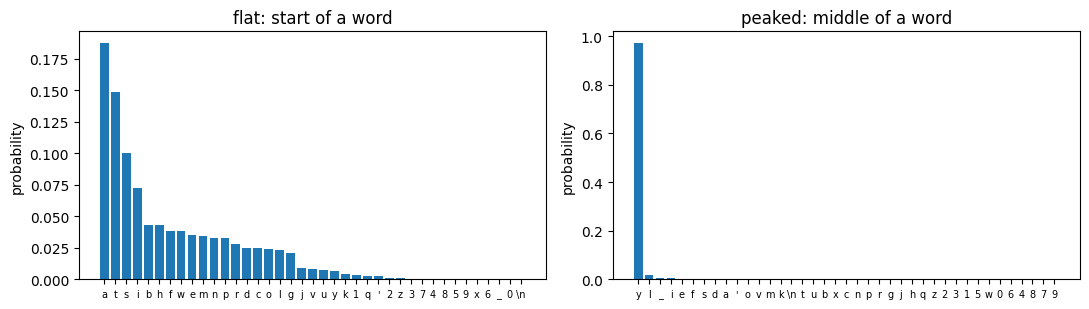

In [5]:
def next_logits(seqs):
    """seqs: a list of id lists. Returns (len(seqs), V) logits for the character that follows each."""
    buf = np.zeros((len(seqs), CONTEXT), dtype=np.int32)
    last = np.zeros(len(seqs), dtype=np.int64)
    for i, s in enumerate(seqs):
        recent = s[-CONTEXT:]
        buf[i, :len(recent)] = recent                 # filler to the right is invisible
        last[i] = len(recent) - 1
    out = model.predict_on_batch(buf)
    return out[np.arange(len(seqs)), last].astype(np.float64)


def softmax(z):
    z = np.asarray(z, dtype=np.float64)
    e = np.exp(z - z.max(axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)


def log_softmax(z):
    z = np.asarray(z, dtype=np.float64)
    m = z.max(axis=-1, keepdims=True)
    return z - m - np.log(np.exp(z - m).sum(axis=-1, keepdims=True))


def entropy(p):
    p = p[p > 0]
    return float(-(p * np.log(p)).sum())


def show(ch):
    return {"\n": "\\n", " ": "_"}.get(ch, ch)


def describe(name, logits, top=8):
    p = softmax(logits)
    order = np.argsort(-p)
    cum = np.cumsum(p[order])
    print(f"{name}")
    print("   " + "  ".join(f"{show(ALPHABET[i])} {p[i]:.3f}" for i in order[:top]))
    print(f"   likeliest {p[order[0]]:.3f} | entropy {entropy(p):.2f} nats = as if {np.exp(entropy(p)):.1f} equal choices"
          f" | {int(np.searchsorted(cum, 0.9) + 1)} characters cover 90% | {(p < 0.01).sum()} of {V} are below 1%")


FLAT_PROMPT, PEAK_PROMPT = "\nthis movie was ", "\nthis movie was absolutel"
flat_logits, peak_logits = next_logits([list(encode(FLAT_PROMPT)), list(encode(PEAK_PROMPT))])
describe("FLAT table, after 'this movie was '", flat_logits)
describe("PEAKED table, after 'this movie was absolutel'", peak_logits)
flat_p = softmax(flat_logits)
flat_order = np.argsort(-flat_p)[:20]
print("the flat table, sorted, first 20 of 39:")
print("   character    ", " ".join(f"{show(ALPHABET[i]):>5s}" for i in flat_order))
print("   probability  ", " ".join(f"{flat_p[i]:.3f}" for i in flat_order))
print("   running total", " ".join(f"{q:.3f}" for q in np.cumsum(flat_p[flat_order])))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, lg, title in [(axes[0], flat_logits, "flat: start of a word"), (axes[1], peak_logits, "peaked: middle of a word")]:
    p = softmax(lg); order = np.argsort(-p)
    ax.bar(range(V), p[order]); ax.set_xticks(range(V)); ax.set_xticklabels([show(ALPHABET[i]) for i in order], fontsize=7)
    ax.set_title(title); ax.set_ylabel("probability")
plt.tight_layout(); plt.show()

### Why we see this

The same model, two very different tables. At the start of a word it spreads its belief over a dozen or more
letters. In the middle of a word it is nearly certain. A good decoding rule has to behave sensibly on
**both**, and that is the test we will put every rule to.

The entropy line turns a table into one number: "as if this many equally likely choices". It is the
perplexity of Chapter 35, for one position.

---
## Step 6 - The loop, and the simplest rule: greedy

The whole of text generation is this loop: **get the table, pick one token, append it, repeat**. The model's
own output becomes its next input, which is why it is called *autoregressive*.

`decode_text()` is that loop, for several prompts at once. The rule is passed in as a function
`pick(logits, history, g)` that returns one id. Alongside the text, the loop records the log-probability
the model's own table gave to each chosen character. We will need that in Step 15.

The first rule is **greedy**: always take the likeliest character.

> **Predict:** 200 characters of greedy text. Fluent? Varied? What happens in the long run when a rule with
> no randomness feeds on its own output?

In [6]:
def decode_text(pick, prompts, n_chars=200, seed=0):
    """The autoregressive loop. Returns the texts (prompt included) and an array (len(prompts), n_chars) of the
    log-probability that the model's own, unmodified table gave to each chosen character."""
    g = np.random.default_rng(seed)
    seqs = [list(encode(p)) for p in prompts]
    logps = np.zeros((len(seqs), n_chars))
    for t in range(n_chars):
        L = next_logits(seqs)                         # 1. the table
        for i, s in enumerate(seqs):
            j = pick(L[i], s, g)                      # 2. the rule picks
            logps[i, t] = log_softmax(L[i])[j]
            s.append(j)                               # 3. append, and go round again
    return [decode(s) for s in seqs], logps


def greedy(logits, history, g):
    return int(np.argmax(logits))


def find_loop(text, min_repeats=3):
    """The shortest block that the text ends by repeating at least min_repeats times, or None."""
    for size in range(1, len(text) // min_repeats + 1):
        block = text[-size:]
        if text.endswith(block * min_repeats):
            return block
    return None


texts, lp = decode_text(greedy, [FLAT_PROMPT], 200)
greedy_text = texts[0]
print(repr(greedy_text[1:]))
print(f"\nmean log-probability per character: {lp.mean():.3f}   (the model's own validation loss is {final_val:.3f}, so real text scores about {-final_val:.3f})")
block = find_loop(greedy_text)
print("it ends in a loop, repeating:", repr(block), f"({len(block)} characters)" if block else "")

'this movie was a movie in the story the story the story the story the story the story the story the story the story the story the story the story the story the story the story the story the story the story the story'

mean log-probability per character: -0.796   (the model's own validation loss is 1.511, so real text scores about -1.511)
it ends in a loop, repeating: ' the story' (10 characters)


### Why we see this

Greedy text is made of real, common words, and it soon falls into a **loop**. The reason is mechanical.
Greedy decoding has no randomness, so the same recent characters always produce the same next character.
This model leans on only its most recent characters (Chapter 35 measured that), so once a stretch of text
comes round again, everything after it must come round again too. Bigger models take longer to fall in, but
the trap is the same.

Look at the log-probability. Greedy text scores far **better** than real text does under the same model.
The model is more confident about this loop than about anything a person wrote. Keep that in mind: it is the
central surprise of the lab.

---
## Step 7 - Pure sampling, and the tail

The opposite rule: **draw from the table exactly as the model gave it**. A character with probability 0.03
gets picked 3 times in 100. This is the honest rule, in that the text is distributed the way the model
believes text is distributed.

Its weakness is the **tail**: the many unlikely entries. Each is rare. Together they are not. We measure the
tail on 1,536 real tables from validation text, and then on a table built by hand with 50,000 entries, the
size of a real vocabulary.

> **Predict:** (1) how much probability, on average, sits outside TinyGPT's five likeliest characters?
> (2) In a 50,000-entry table whose entries beyond rank 1,000 each have a probability below 0.006%, how much
> do those 49,000 entries hold together?

In [7]:
def pure(logits, history, g):
    p = softmax(logits)
    return int(g.choice(len(p), p=p))


texts, lp = decode_text(pure, [FLAT_PROMPT], 200, seed=1)
print(repr(texts[0][1:]))
print(f"mean log-probability per character: {lp.mean():.3f}")

# many real tables at once: positions 16..63 of 32 validation windows
many_logits = model.predict(x_val[:32], batch_size=32, verbose=0)[:, 16:, :].reshape(-1, V).astype(np.float64)
P = softmax(many_logits)
P_sorted = -np.sort(-P, axis=1)
cum = np.cumsum(P_sorted, axis=1)
print(f"\n{len(P):,} real tables from validation text:")
print(f"   likeliest character: median {np.median(P_sorted[:, 0]):.2f}; above 0.9 in {np.mean(P_sorted[:, 0] > 0.9):.0%} of tables, below 0.3 in {np.mean(P_sorted[:, 0] < 0.3):.0%}")
print(f"   probability outside the top 5:  mean {1 - cum[:, 4].mean():.3f}, largest {1 - cum[:, 4].min():.3f}")
print(f"   probability outside the top 10: mean {1 - cum[:, 9].mean():.3f}")
tail_small = np.where(P < 0.01, P, 0).sum(axis=1)
print(f"   probability held by characters that are each below 1%: mean {tail_small.mean():.3f}")
print(f"   so in 200 sampled characters expect about {200 * tail_small.mean():.0f} that the model itself rated below 1%")

# a hand-made table the size of a real vocabulary: probability proportional to 1 / rank^1.2
rank = np.arange(1, 50_001)
big = rank ** -1.2
big /= big.sum()
big_cum = np.cumsum(big)
print("\na HAND-MADE table with 50,000 entries (not measured from any model):")
print(f"   top entry {big[0]:.3f}; top 10 hold {big_cum[9]:.3f}; top 50 hold {big_cum[49]:.3f}")
print(f"   entry 1,001 has probability {big[1000]:.6f}; entries 1,001 to 50,000 hold {1 - big_cum[999]:.3f} together")
print(f"   so in 200 sampled tokens expect about {200 * (1 - big_cum[999]):.0f} from beyond rank 1,000")

'this movie was kubt it maronic and semself by also and romance but do around rite only the protect the give 4 i one or the years really to in englixenser last more by examed through untiled nary shel eyes that incee'
mean log-probability per character: -1.599



1,536 real tables from validation text:
   likeliest character: median 0.50; above 0.9 in 17% of tables, below 0.3 in 28%
   probability outside the top 5:  mean 0.148, largest 0.608
   probability outside the top 10: mean 0.061
   probability held by characters that are each below 1%: mean 0.029
   so in 200 sampled characters expect about 6 that the model itself rated below 1%

a HAND-MADE table with 50,000 entries (not measured from any model):
   top entry 0.199; top 10 hold 0.492; top 50 hold 0.660
   entry 1,001 has probability 0.000050; entries 1,001 to 50,000 hold 0.136 together
   so in 200 sampled tokens expect about 27 from beyond rank 1,000


### Why we see this

Sampled text is more varied than greedy text and never loops, and it contains more invented words. Each
invented word began with one unlucky draw from the tail, after which the model had to carry on from a place
it had never seen in training. That is how errors **compound** in an autoregressive loop: the model is never
shown its own mistakes during training, so it has no practice at recovering from them.

On 39 characters the tail is short. On the hand-made 50,000-entry table it is long, and this is the picture
to carry to full-size models: no single tail token is likely, yet a noticeable share of all draws lands
somewhere in the tail. Top-k, top-p and min-p (Steps 9 to 11) are three ways of cutting it off.

---
## Step 8 - Temperature: one knob for the shape of the table

**Divide every logit by a number T before the softmax.** That is all temperature is.

* T below 1 stretches the gaps between logits: the table gets peakier.
* T = 1 leaves the model's own table.
* T above 1 shrinks the gaps: the table gets flatter.

First on a table small enough to check by hand: four tokens with logits 2, 1, 0, −1.

> **Predict:** the top token has probability 0.644 at T = 1. Will it be nearer 0.75, 0.85 or 0.95 at T = 0.5?
> And at T = 2?

In [8]:
toy = np.array([2.0, 1.0, 0.0, -1.0])
print("logits", toy)
for T in [0.25, 0.5, 1.0, 2.0, 4.0]:
    p = softmax(toy / T)
    print(f"T = {T:<4}  p = {np.round(p, 3)}   entropy {entropy(p):.3f}  (as if {np.exp(entropy(p)):.2f} choices)")
print("T -> 0 gives [1, 0, 0, 0] (greedy);  T -> infinity gives [0.25, 0.25, 0.25, 0.25] (a blind guess)")

print("\nthe FLAT real table at three temperatures (top 6 characters):")
order = np.argsort(-flat_logits)[:6]
for T in [0.5, 1.0, 1.5]:
    p = softmax(flat_logits / T)
    print(f"T = {T}:  " + "  ".join(f"{show(ALPHABET[i])} {p[i]:.3f}" for i in order) + f"   | as if {np.exp(entropy(p)):.1f} choices")


def with_temperature(T):
    def pick(logits, history, g):
        p = softmax(np.asarray(logits) / T)
        return int(g.choice(len(p), p=p))
    return pick


print()
for T in [0.5, 1.0, 1.5]:
    texts, lp = decode_text(with_temperature(T), [FLAT_PROMPT], 160, seed=1)
    print(f"T = {T}  (mean log-prob {lp.mean():.2f})")
    print("   ", repr(texts[0][1:]))

logits [ 2.  1.  0. -1.]
T = 0.25  p = [0.982 0.018 0.    0.   ]   entropy 0.093  (as if 1.10 choices)
T = 0.5   p = [0.865 0.117 0.016 0.002]   entropy 0.455  (as if 1.58 choices)
T = 1.0   p = [0.644 0.237 0.087 0.032]   entropy 0.948  (as if 2.58 choices)
T = 2.0   p = [0.455 0.276 0.167 0.102]   entropy 1.245  (as if 3.47 choices)
T = 4.0   p = [0.35  0.273 0.212 0.165]   entropy 1.348  (as if 3.85 choices)
T -> 0 gives [1, 0, 0, 0] (greedy);  T -> infinity gives [0.25, 0.25, 0.25, 0.25] (a blind guess)

the FLAT real table at three temperatures (top 6 characters):
T = 0.5:  a 0.401  t 0.253  s 0.114  i 0.060  b 0.021  h 0.021   | as if 6.6 choices
T = 1.0:  a 0.187  t 0.149  s 0.100  i 0.073  b 0.043  h 0.043   | as if 16.3 choices
T = 1.5:  a 0.122  t 0.104  s 0.080  i 0.065  b 0.046  h 0.046   | as if 22.4 choices



T = 0.5  (mean log-prob -0.93)
    'this movie was it was be the film is could but the acting is a could be to day the story say the set the scenes the movie human the movie is a few with the movie that it was t'


T = 1.0  (mean log-prob -1.61)
    'this movie was kubt it maronic and semself by also and romance but do around rite only the protect the give 4 i one or the years really to in englixenser last more by examed t'


T = 1.5  (mean log-prob -2.33)
    "this movie was lucweknam sodped i'll just edul othn michonds mr too scaston 1879 dory jurk puttoduct the peo0 i'ongeouse maze also her music all foursonshian bothh cultuite dr"


### Why we see this

Temperature never changes the **order** of the tokens. The likeliest stays likeliest at every T. What changes
is how much probability the leaders hold. At T = 0.5 the text is cautious and repetitive, close to greedy.
At T = 1.5 the tail is fed, and the text fills with strings that are not words.

Notice what temperature did **not** do: it did not make the model cleverer or more imaginative. The model
and its knowledge are the same at every setting. Temperature moves one thing: how often the decoder takes
the model's second, third and thirtieth guesses instead of its first.

---
## Step 9 - Top-k: keep the k likeliest, throw the rest away

Sort the table, keep the top k entries, set the others to zero and **renormalise** so that what is left sums
to 1. In logit terms: set every logit outside the top k to minus infinity and take the softmax again.

Full-size systems use k of 40 or 50 on 50,000 tokens. With 39 characters that would cut nothing, so here we
use **k = 5**.

> **Predict:** how much of the probability does k = 5 keep on the flat table? On the peaked table? In which
> case is 5 too few, and in which is it too many?

In [9]:
def keep_top_k(z, k):
    """Logits outside the k largest become -inf."""
    z = np.array(z, dtype=np.float64)
    cut = np.sort(z)[-k]
    z[z < cut] = -np.inf
    return z


def kept(z):
    return int(np.isfinite(z).sum())


for name, lg in [("flat", flat_logits), ("peaked", peak_logits)]:
    p = softmax(lg)
    z = keep_top_k(lg, 5)
    q = softmax(z)
    order = np.argsort(-p)[:7]
    print(f"{name:6s} table, k = 5: keeps {kept(z)} characters holding {p[np.isfinite(z)].sum():.3f} of the probability")
    print("   before: " + "  ".join(f"{show(ALPHABET[i])} {p[i]:.3f}" for i in order))
    print("   after : " + "  ".join(f"{show(ALPHABET[i])} {q[i]:.3f}" for i in order))
    print(f"   the 5th character kept had probability {np.sort(p)[-5]:.4f}")

top5_mass = cum[:, 4]
print(f"\nover the {len(P):,} real tables, k = 5 keeps: less than 80% of the probability in {np.mean(top5_mass < 0.8):.0%} of tables,")
print(f"   and in {np.mean(P_sorted[:, 4] < 0.001):.0%} of tables its 5th character is below 0.1% (kept anyway)")

flat   table, k = 5: keeps 5 characters holding 0.552 of the probability
   before: a 0.187  t 0.149  s 0.100  i 0.073  b 0.043  h 0.043  f 0.039
   after : a 0.340  t 0.270  s 0.181  i 0.131  b 0.079  h 0.000  f 0.000
   the 5th character kept had probability 0.0434
peaked table, k = 5: keeps 5 characters holding 0.997 of the probability
   before: y 0.972  l 0.017  _ 0.004  i 0.004  e 0.001  f 0.001  s 0.000
   after : y 0.974  l 0.017  _ 0.004  i 0.004  e 0.001  f 0.000  s 0.000
   the 5th character kept had probability 0.0006

over the 1,536 real tables, k = 5 keeps: less than 80% of the probability in 27% of tables,
   and in 4% of tables its 5th character is below 0.1% (kept anyway)


### Why we see this

A fixed k is wrong in both directions. On the flat table five is **too few**: it throws away reasonable
letters that together held a real share of the probability. On the peaked table five is **too many**: it
keeps characters the model gave almost no chance, when the honest shortlist had one name on it. The table
changes shape at every step and k does not.

---
## Step 10 - Top-p (nucleus): keep the smallest set that holds probability p

Sort the table. Walk down it, adding up probabilities, and stop as soon as the running total reaches p. Keep
what you passed, drop the rest, renormalise. The number of survivors now **adapts** to the table.

> **Predict:** with p = 0.9, how many characters survive on the flat table and on the peaked table? Over all
> the real tables, what are the smallest and largest nucleus you expect?

flat   table, p = 0.5 : nucleus of  4 characters, holding 0.508
flat   table, p = 0.9 : nucleus of 16 characters, holding 0.908
flat   table, p = 0.99: nucleus of 24 characters, holding 0.990
peaked table, p = 0.5 : nucleus of  1 characters, holding 0.972
peaked table, p = 0.9 : nucleus of  1 characters, holding 0.972
peaked table, p = 0.99: nucleus of  3 characters, holding 0.993

nucleus size at p = 0.9 over 1,536 real tables: smallest 1, median 5, mean 6.3, largest 17
   a nucleus of exactly 1 (top-p acts like greedy) in 17% of tables

hand-made 50,000-entry tables: the unsure one (1/rank^1.2) has a 0.9-nucleus of 2,166 entries;
   a sure one (1/rank^3, top entry 0.832) has a 0.9-nucleus of 2


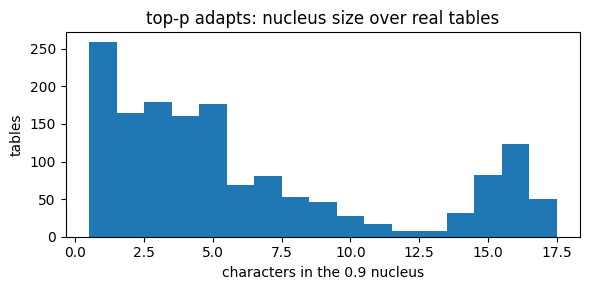

In [10]:
def keep_top_p(z, p_keep):
    """Keep the smallest set of entries whose probability reaches p_keep; the rest become -inf."""
    z = np.array(z, dtype=np.float64)
    p = softmax(z)
    order = np.argsort(-p)
    before = np.cumsum(p[order]) - p[order]           # probability already collected before each entry
    drop = order[before >= p_keep]
    z[drop] = -np.inf
    return z


for name, lg in [("flat", flat_logits), ("peaked", peak_logits)]:
    for pk in [0.5, 0.9, 0.99]:
        z = keep_top_p(lg, pk)
        print(f"{name:6s} table, p = {pk:<4}: nucleus of {kept(z):2d} characters, holding {softmax(lg)[np.isfinite(z)].sum():.3f}")

nucleus = (np.cumsum(P_sorted, axis=1) - P_sorted < 0.9).sum(axis=1)
print(f"\nnucleus size at p = 0.9 over {len(P):,} real tables: smallest {nucleus.min()}, median {int(np.median(nucleus))}, mean {nucleus.mean():.1f}, largest {nucleus.max()}")
print(f"   a nucleus of exactly 1 (top-p acts like greedy) in {np.mean(nucleus == 1):.0%} of tables")
big_nucleus = int(np.searchsorted(big_cum, 0.9) + 1)
sure = rank ** -3.0; sure /= sure.sum()
print(f"\nhand-made 50,000-entry tables: the unsure one (1/rank^1.2) has a 0.9-nucleus of {big_nucleus:,} entries;")
print(f"   a sure one (1/rank^3, top entry {sure[0]:.3f}) has a 0.9-nucleus of {int(np.searchsorted(np.cumsum(sure), 0.9) + 1)}")

plt.figure(figsize=(6, 3))
plt.hist(nucleus, bins=np.arange(0.5, nucleus.max() + 1.5)); plt.xlabel("characters in the 0.9 nucleus"); plt.ylabel("tables")
plt.title("top-p adapts: nucleus size over real tables"); plt.tight_layout(); plt.show()

### Why we see this

Top-p asks a different question from top-k. Not "how many candidates?" but "how much of the model's belief
do I keep?". When the model is sure, the nucleus is one character and top-p behaves like greedy. When the
model is unsure, the nucleus widens to a dozen or more. That is why top-p became the usual default for
open-ended writing.

It has its own weak spot, which the hand-made table shows: on a very flat table, 90% of the probability can
be thousands of entries, most of them poor. Top-p lets them all in.

---
## Step 11 - Min-p: a floor that moves with the leader

Min-p keeps every token whose probability is at least a fraction of the **top** token's. With min-p = 0.1 and
a leader at 0.60, the floor is 0.06. With a leader at 0.08, the floor is 0.008.

> **Predict:** on the peaked table the leader is close to 1. What is the floor at min-p = 0.1, and how many
> characters clear it?

In [11]:
def keep_min_p(z, min_p):
    """Keep entries whose probability is at least min_p times the largest probability."""
    z = np.array(z, dtype=np.float64)
    p = softmax(z)
    z[p < min_p * p.max()] = -np.inf
    return z


for name, lg in [("flat", flat_logits), ("peaked", peak_logits)]:
    p = softmax(lg)
    for mp in [0.05, 0.1, 0.3]:
        z = keep_min_p(lg, mp)
        print(f"{name:6s} table, min-p = {mp:<4}: floor {mp * p.max():.4f}, keeps {kept(z):2d} characters holding {p[np.isfinite(z)].sum():.3f}")

minp_kept = (P >= 0.1 * P.max(axis=1, keepdims=True)).sum(axis=1)
print(f"\nmin-p = 0.1 over {len(P):,} real tables: keeps between {minp_kept.min()} and {minp_kept.max()} characters, mean {minp_kept.mean():.1f}")
print(f"hand-made unsure table (50,000 entries): min-p = 0.1 keeps {(big >= 0.1 * big[0]).sum()} entries; top-p = 0.9 kept {big_nucleus:,}")

flat   table, min-p = 0.05: floor 0.0094, keeps 18 characters holding 0.952
flat   table, min-p = 0.1 : floor 0.0187, keeps 18 characters holding 0.952
flat   table, min-p = 0.3 : floor 0.0562, keeps  4 characters holding 0.508
peaked table, min-p = 0.05: floor 0.0486, keeps  1 characters holding 0.972
peaked table, min-p = 0.1 : floor 0.0972, keeps  1 characters holding 0.972
peaked table, min-p = 0.3 : floor 0.2915, keeps  1 characters holding 0.972

min-p = 0.1 over 1,536 real tables: keeps between 1 and 21 characters, mean 5.7
hand-made unsure table (50,000 entries): min-p = 0.1 keeps 6 entries; top-p = 0.9 kept 2,166


### Why we see this

Min-p adapts like top-p, but it measures each token against the leader, not against a running total. Its
promise is simple: nothing gets in that the model thinks is more than ten times less likely than its best
guess. On the flat hand-made table, where top-p lets in thousands of entries, min-p keeps a handful.

---
## Step 12 - Order of operations: one function for all the knobs

Real decoders apply several of these at once, and **the order matters**:

1. penalties (they edit logits of tokens already used)
2. temperature (divide the logits)
3. truncation (top-k, top-p, min-p)
4. renormalise (a softmax over what is left)
5. sample

`choose()` does exactly that, and every later step uses it. The cell also shows why temperature must come
**before** truncation: at T = 1.5 the table is flatter, so the 0.9 nucleus should be larger. Truncate first
and you get the small nucleus of T = 1, then reheat only the survivors.

> **Predict:** on the flat table, is the 0.9 nucleus at T = 1.5 larger or smaller than at T = 1? By how much?

In [12]:
def penalise_repeats(z, history, theta, window=32):
    """Repetition penalty: logits of tokens seen in the last `window` positions are pushed down.
    Positive logits are divided by theta and negative ones multiplied by it."""
    z = np.array(z, dtype=np.float64)
    for j in set(history[-window:]):
        z[j] = z[j] / theta if z[j] > 0 else z[j] * theta
    return z


def block_ngrams(z, history, n):
    """No-repeat n-gram blocking: forbid any token that would complete an n-gram already present in history."""
    z = np.array(z, dtype=np.float64)
    if len(history) >= n:
        tail = history[len(history) - (n - 1):]
        for i in range(len(history) - n + 1):
            if history[i:i + n - 1] == tail:
                z[history[i + n - 1]] = -np.inf
    return z


def choose(logits, history, g, temperature=1.0, top_k=None, top_p=None, min_p=None,
           rep_penalty=None, rep_window=32, no_repeat=None, bias=None, greedy=False):
    z = np.array(logits, dtype=np.float64)
    if bias is not None:
        z = z + bias                                                  # 0. logit bias (Step 16)
    if rep_penalty:
        z = penalise_repeats(z, history, rep_penalty, rep_window)     # 1. penalties
    if no_repeat:
        z = block_ngrams(z, history, no_repeat)
    if greedy:
        return int(np.argmax(z))
    z = z / temperature                                               # 2. temperature
    if top_k:
        z = keep_top_k(z, top_k)                                      # 3. truncation
    if top_p:
        z = keep_top_p(z, top_p)
    if min_p:
        z = keep_min_p(z, min_p)
    p = softmax(z)                                                    # 4. renormalise
    return int(g.choice(len(p), p=p))                                 # 5. sample


def rule(**knobs):
    return lambda logits, history, g: choose(logits, history, g, **knobs)


right = keep_top_p(flat_logits / 1.5, 0.9)                 # temperature, then truncation
wrong = keep_top_p(flat_logits, 0.9)                       # truncation first ...
print(f"flat table, top-p 0.9 at T = 1  : nucleus of {kept(wrong)}")
print(f"temperature 1.5 THEN top-p 0.9   : nucleus of {kept(right)}   (the usual order)")
print(f"top-p 0.9 THEN temperature 1.5   : nucleus of {kept(wrong)}, reheated: its last member rises from "
      f"{np.sort(softmax(wrong))[-kept(wrong)]:.3f} to {np.sort(softmax(wrong / 1.5))[-kept(wrong)]:.3f}")
both = keep_top_p(keep_top_k(flat_logits, 30), 0.9)
print(f"\ntop-k 30 and top-p 0.9 together: {kept(both)} survive; top-p alone: {kept(keep_top_p(flat_logits, 0.9))}. Here top-k = 30 did nothing.")

texts, lp = decode_text(rule(temperature=0.8, top_p=0.9), [FLAT_PROMPT], 160, seed=1)
print("\nT = 0.8 with top-p 0.9:", repr(texts[0][1:]))

flat table, top-p 0.9 at T = 1  : nucleus of 16
temperature 1.5 THEN top-p 0.9   : nucleus of 19   (the usual order)
top-p 0.9 THEN temperature 1.5   : nucleus of 16, reheated: its last member rises from 0.026 to 0.037

top-k 30 and top-p 0.9 together: 16 survive; top-p alone: 16. Here top-k = 30 did nothing.



T = 0.8 with top-p 0.9: "this movie was it was he some make the world i real me or don't some carry carry but between the screen he hand show the mix earth is inconful diection the middle may friend t"


### Why we see this

Both orders are legal arithmetic and they give different decoders. Libraries differ in the order they use
and some let you choose it, so the same "temperature 1.5, top-p 0.9" can mean two things. When a result
depends on decoding settings, write down the order as well as the values.

The last line is the commonest careless setting: two truncation rules where one is so loose that it never
acts. Nothing breaks. One of your knobs is simply not connected to anything.

---
## Step 13 - Fighting repetition: a penalty, and a block

Two tools aimed at the loop of Step 6.

* A **repetition penalty** pushes down the logit of every token that appeared recently (here: in the last
  32 characters).
* **No-repeat n-gram blocking** forbids any token that would complete a run of n tokens already written.

Both were designed for subword tokens, where a token is a piece of a word. Here a token is a **character**,
and every English word is built from the same few characters. That makes this lab a harsh and useful test.

From here on we measure text instead of only reading it, on eight prompts of 200 characters each:

* **repeats**: the share of 6-character runs that already occurred earlier in the same text.
* **real words**: the share of words that occur anywhere in the training reviews. A rough spelling score.

> **Predict:** (1) will a penalty of 1.3 break the greedy loop? (2) What will a penalty of 2.0 do to
> spelling? (3) Add the penalty to a sampler that was not looping (T 0.8 with top-p 0.9). Better or worse?

In [13]:
def measure(continuations):
    """Mean over texts of: repeated 6-character runs, share of real words, distinct characters, distinct words per 100 words."""
    rep, real, chars, wordvar = [], [], [], []
    for c in continuations:
        grams = [c[i:i + 6] for i in range(len(c) - 5)]
        rep.append(1 - len(set(grams)) / len(grams))
        words = c.split()[1:-1]                                   # the first and last may be cut in half
        real.append(np.mean([w in real_words for w in words]) if words else 0.0)
        chars.append(len(set(c)))
        wordvar.append(100 * len(set(words)) / max(1, len(words)))
    return float(np.mean(rep)), float(np.mean(real)), float(np.mean(chars)), float(np.mean(wordvar))


PROMPTS = ["\nthis movie was ", "\nthe acting is ", "\ni have never seen ", "\nthe story of the ",
           "\none of the best ", "\nit is hard to ", "\nwhat a waste of ", "\nthe director has "]
N_SCORE = 200
results = {}                # name -> (log-prob, repeats, real words, chars, words per 100, first text)


def run_rule(name, r):
    texts, lp = decode_text(r, PROMPTS, N_SCORE, seed=7)
    results[name] = (float(lp.mean()), *measure([t[len(p):] for t, p in zip(texts, PROMPTS)]), texts[0])
    return results[name]


print(f"{'rule':38s} {'repeats':>8s} {'real words':>10s}")
for name, r in [("greedy", rule(greedy=True)),
                ("greedy + repetition penalty 1.3", rule(greedy=True, rep_penalty=1.3)),
                ("greedy + repetition penalty 2.0", rule(greedy=True, rep_penalty=2.0)),
                ("greedy + no repeated 8-grams", rule(greedy=True, no_repeat=8)),
                ("greedy + no repeated 4-grams", rule(greedy=True, no_repeat=4)),
                ("T 0.8 + top-p 0.9", rule(temperature=0.8, top_p=0.9)),
                ("T 0.8 + top-p 0.9 + penalty 1.3", rule(temperature=0.8, top_p=0.9, rep_penalty=1.3)),
                ("T 0.8 + top-p 0.9 + penalty 2.0", rule(temperature=0.8, top_p=0.9, rep_penalty=2.0))]:
    lpm, rep, real, chars, wv, first = run_rule(name, r)
    print(f"{name:38s} {rep:8.1%} {real:10.1%}")
    print("      ", repr(first[1:100]))

recent = set(encode(results["T 0.8 + top-p 0.9"][5])[-32:].tolist())
print(f"\ndistinct characters in the last 32 of a sampled text: {len(recent)} of {V}: {''.join(show(ALPHABET[i]) for i in sorted(recent))}")
print(f"the flat table has {int((flat_logits > 0).sum())} positive and {int((flat_logits < 0).sum())} negative logits: the penalty divides the first kind and multiplies the second")

rule                                    repeats real words


greedy                                    93.6%     100.0%
       'this movie was a movie in the story the story the story the story the story the story the story the'


greedy + repetition penalty 1.3           22.9%      99.1%
       'this movie was all the first of the completely was a great in the film to be the could with a serie'


greedy + repetition penalty 2.0            7.8%      84.2%
       "this movie was budgern fly cop the story impratived but whole confused they're agimative whole beck"


greedy + no repeated 8-grams              19.8%      96.8%
       'this movie was a movie in the story the strange the start the student the screen the scenes the sti'


greedy + no repeated 4-grams               0.0%      81.5%
       'this movie was a more than the story think though througot thum it is an a considering th to see to'


T 0.8 + top-p 0.9                          2.6%      93.3%
       "this movie was riva film didn't was don't think and with the the first of the same the patture fami"


T 0.8 + top-p 0.9 + penalty 1.3            0.7%      82.0%
       "this movie was now all huge that's chry strippt and worth a full few minks dryight scene would bad "


T 0.8 + top-p 0.9 + penalty 2.0            0.3%      48.8%
       "this movie was mys and gues thero's explosics walking it\ntadum by frankersonsince drawingshunt have"

distinct characters in the last 32 of a sampled text: 15 of 39: _acdefhimnoprst
the flat table has 22 positive and 17 negative logits: the penalty divides the first kind and multiplies the second


### Why we see this

The penalty does break the loop, and the price depends steeply on its strength. At 1.3 on top of greedy the
words are still words. At 2.0 the spelling starts to go. Added to a sampler that was **not** looping, the
penalty has nothing to fix and only does harm: the share of real words falls, and at 2.0 it collapses.

The reason is in the second-to-last line. In any 32 characters of English you have already used the space,
`e`, `t`, `a` and most of the letters the next word needs. The penalty is aimed at exactly those. This is the
lab's small-scale version of a real problem: **a repetition penalty cannot tell a bad repeat from a necessary
one**. At full size the victims are names, numbers, variable names in code and the closing bracket you opened
three lines ago.

N-gram blocking with a long n is gentler, because it only forbids long exact repeats. Shorten n and it turns
destructive too: forbid every repeated 4-character run and a common word such as `the` can hardly be
written twice.

The last line is a quirk worth knowing. This penalty divides positive logits and multiplies negative ones, so
its effect depends on where zero happens to sit, which a softmax does not care about at all.

---
## Step 14 - Beam search: look for the single most probable text

Greedy takes the best next character. That is not the same as the best **sequence**: a slightly worse
character now may open the way to much better ones later. Beam search keeps the **B best partial texts**
(the beam). At each step it extends every one of them by every likely character, scores each extension by
its total log-probability, and keeps the best B again.

We run widths 1, 3 and 10 for 120 characters. (All our candidates have the same length, so we do not need
length normalisation here; the chapter explains when you do.)

> **Predict:** (1) is width 1 the same as greedy? (2) As the width grows, does the total log-probability go
> up or down? (3) Does the text get more interesting?

In [14]:
def beam_search(prompt, width, n_chars):
    """Returns the final beam: a list of (total log-probability, ids), best first."""
    beams = [(0.0, list(encode(prompt)))]
    for _ in range(n_chars):
        L = log_softmax(next_logits([s for _, s in beams]))
        candidates = []
        for (score, s), row in zip(beams, L):
            for j in np.argsort(-row)[:width]:                       # only the `width` best extensions can survive
                candidates.append((score + row[j], s + [int(j)]))
        candidates.sort(key=lambda c: -c[0])
        beams = candidates[:width]                                   # prune
    return beams


N_BEAM = 120
beam_results = {}
for width in [1, 3, 10]:
    t0 = time.time()
    beams = beam_search(FLAT_PROMPT, width, N_BEAM)
    score, ids = beams[0]
    beam_results[width] = (score, decode(ids))
    print(f"width {width:2d}: total log-prob {score:8.2f}  per character {score / N_BEAM:.3f}  [{time.time() - t0:.1f}s]")
    print("   ", repr(decode(ids)[1:]))
assert beam_results[1][1] == greedy_text[:len(FLAT_PROMPT) + N_BEAM], "width 1 must equal greedy"
print("\nwidth 1 is greedy: identical text")
texts, lp = decode_text(pure, [FLAT_PROMPT] * 4, N_BEAM, seed=5)
print(f"for comparison, four pure samples of the same length score {', '.join(f'{v:.0f}' for v in lp.sum(axis=1))} in total")
score10, ids10 = beam_search(FLAT_PROMPT, 10, N_BEAM)[-1]
print(f"the 10th-best text in the width-10 beam differs from the best in {sum(a != b for a, b in zip(ids10, ids))} of {N_BEAM} characters")

width  1: total log-prob   -95.78  per character -0.798  [0.3s]
    'this movie was a movie in the story the story the story the story the story the story the story the story the story the story the story'


width  3: total log-prob   -76.30  per character -0.636  [0.4s]
    'this movie was the film that this movie that this movie that the movie that this movie that the movie that this movie that the movie is'


width 10: total log-prob   -73.37  per character -0.611  [0.7s]
    'this movie was this movie that this movie this movie that this movie in the movie that this movie that this movie that this movie that '

width 1 is greedy: identical text


for comparison, four pure samples of the same length score -213, -217, -181, -192 in total


the 10th-best text in the width-10 beam differs from the best in 3 of 120 characters


### Why we see this

Beam search does what it promises: wider beams find texts with a higher total probability, far higher than
any sample. And the text is **worse**: shorter loops, commoner words, entered sooner. The most probable
sequence under a language model is a bland, repetitive one, because blandness is what is probable.

Look at the last line too. The ten texts in the final beam are nearly the same text. A beam spends most of
its width on variations of one idea.

So why does beam search exist? Because for some tasks there **is** one right answer and it is short:
a translation, a transcription, a summary of a given text (Chapter 21). There, "the most probable output"
and "the best output" are close. In open-ended writing they are not.

---
## Step 15 - The scoreboard

Now every rule on the same eight prompts, 200 characters each. To the two measurements of Step 13 we add:

* **log-prob**: mean log-probability per character under the model's own table. Higher means the model finds
  the text more likely.
* **chars** and **words/100**: how many different characters, and how many different words per 100 words,
  were used. Variety.

The first row is **real text**: eight passages from validation reviews, scored by the same model.

> **Predict:** which rule will come closest to the real-text row on log-probability and on repeats? Which
> will have the best log-probability and be the worst text?

rule                               log-prob  repeats real words  chars words/100
REAL TEXT (validation reviews)        -1.44     1.4%      98.2%   23.9      85.8
greedy                                -0.80    93.6%     100.0%    9.2       6.5
temperature 0.5                       -1.00     9.4%      96.6%   22.1      63.1
temperature 0.8                       -1.29     1.9%      84.9%   23.6      81.4
pure sampling (T = 1)                 -1.52     1.0%      76.8%   25.2      90.7
temperature 1.5                       -2.25     0.2%      41.4%   27.4      98.0
top-k 5                               -1.20     4.8%      88.8%   21.6      71.5
top-k 3                               -1.02    11.9%      93.2%   21.4      61.8
top-p 0.9                             -1.23     2.3%      86.7%   23.0      86.6
min-p 0.1                             -1.21     2.1%      87.7%   22.4      82.7
T 0.8 + top-p 0.9                     -1.17     2.6%      93.3%   23.0      76.7
greedy + repetition penalty 

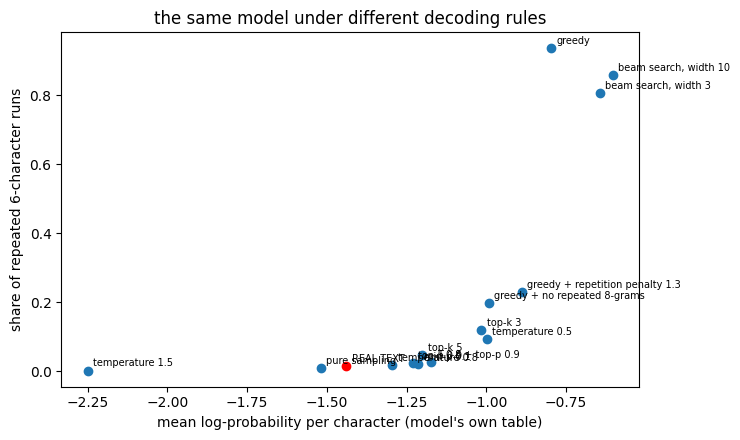

In [15]:
board = []

# real text, scored by the model: teacher forcing, one row per position
val_reviews = [r for r in reviews[n_train_reviews:] if len(r) > 16 + N_SCORE][:len(PROMPTS)]
real_lp, real_cont = [], []
for r in val_reviews:
    ids = [0] + encode(r[:16 + N_SCORE]).tolist()
    L = log_softmax(next_logits([ids[:t] for t in range(17, 17 + N_SCORE)]))
    real_lp.append(L[np.arange(N_SCORE), ids[17:17 + N_SCORE]].mean())
    real_cont.append(r[16:16 + N_SCORE])
board.append(("REAL TEXT (validation reviews)", float(np.mean(real_lp)), *measure(real_cont)))

rules = [("greedy", rule(greedy=True)),
         ("temperature 0.5", rule(temperature=0.5)),
         ("temperature 0.8", rule(temperature=0.8)),
         ("pure sampling (T = 1)", rule()),
         ("temperature 1.5", rule(temperature=1.5)),
         ("top-k 5", rule(top_k=5)),
         ("top-k 3", rule(top_k=3)),
         ("top-p 0.9", rule(top_p=0.9)),
         ("min-p 0.1", rule(min_p=0.1)),
         ("T 0.8 + top-p 0.9", rule(temperature=0.8, top_p=0.9)),
         ("greedy + repetition penalty 1.3", None),
         ("greedy + no repeated 8-grams", None)]
for name, r in rules:
    row = results[name] if name in results else run_rule(name, r)      # Step 13 already ran some of these
    board.append((name, *row[:5]))
for width in [3, 10]:
    conts, scores = [], []
    for p in PROMPTS[:4]:                                         # beam search is slower: four prompts
        score, ids = beam_search(p, width, N_SCORE)[0]
        conts.append(decode(ids)[len(p):]); scores.append(score / N_SCORE)
    board.append((f"beam search, width {width} (4 prompts)", float(np.mean(scores)), *measure(conts)))

print(f"{'rule':34s} {'log-prob':>8s} {'repeats':>8s} {'real words':>10s} {'chars':>6s} {'words/100':>9s}")
for name, lpm, rep, real, chars, wv in board:
    print(f"{name:34s} {lpm:8.2f} {rep:8.1%} {real:10.1%} {chars:6.1f} {wv:9.1f}")

plt.figure(figsize=(7.5, 4.5))
for name, lpm, rep, real, chars, wv in board:
    plt.scatter(lpm, rep, color="red" if name.startswith("REAL") else "tab:blue")
    plt.annotate(name.split(" (")[0], (lpm, rep), fontsize=7, xytext=(4, 3), textcoords="offset points")
plt.xlabel("mean log-probability per character (model's own table)"); plt.ylabel("share of repeated 6-character runs")
plt.title("the same model under different decoding rules"); plt.tight_layout(); plt.show()

### Why we see this

Read the table from the real-text row outwards.

* **Real text is not high-probability text.** People write at about the model's own loss, and repeat little.
* **Greedy and beam search** score far above real text on log-probability and repeat most of what they
  write. They are answering "what is likeliest?", and the likeliest thing is a loop.
* **Pure sampling** matches real text on log-probability and on repetition, which is what "sampling from
  the model" should do, and pays in misspelt words, each begun by a draw from the tail.
* **High temperature** falls below real text: the model itself finds the output implausible.
* **Truncation with a mild temperature** (top-p, min-p, T = 0.8 with top-p) sits between: more real words
  than pure sampling, far less repetition than greedy. That middle is where most systems are set.

No row is "the best". Each rule is a position on a line from *safe and repetitive* to *varied and wrong*, and
the right position depends on the job. Note also what this board cannot see: whether the text is true,
useful or on the subject. At this model size none of it is.

---
## Step 16 - Stopping, and a hand on the scale

The loop has no natural end. Three things can end it:

* the model picks its **end token** (here the newline, id 0),
* the text ends with a **stop string** that you chose,
* a **maximum length** runs out.

Only the first is the model saying "I have finished". The cell samples 16 continuations with a limit of 400
characters, first with pure sampling and then with T 0.8 and top-p 0.9, and counts how each one ended. Then it adds a **logit bias**: a number added to one token's logit
before anything else happens.

> **Predict:** the newline is one character in about 1,300 in the training text. How many of 16 samples will
> stop by themselves within 400 characters with pure sampling? With top-p 0.9? What does a bias of +4 on the
> newline do? A bias of minus infinity?

In [16]:
def sample_until_stop(prompt, n_samples, max_chars, seed, stop_string=None, **knobs):
    """Sample until the end token (id 0), a stop string or max_chars. Returns the texts and how each ended."""
    g = np.random.default_rng(seed)
    start = list(encode(prompt))
    seqs = [list(start) for _ in range(n_samples)]
    ended = ["max length"] * n_samples
    active = list(range(n_samples))
    for _ in range(max_chars):
        if not active:
            break
        L = next_logits([seqs[i] for i in active])
        still = []
        for row, i in zip(L, active):
            j = choose(row, seqs[i], g, **knobs)
            if j == 0:
                ended[i] = "end token"                    # the model said stop; do not append it
            else:
                seqs[i].append(j)
                if stop_string and decode(seqs[i][len(start):]).endswith(stop_string):
                    ended[i] = "stop string"
                else:
                    still.append(i)
        active = still
    return [decode(s[len(start):]) for s in seqs], ended


def report(name, texts, ended):
    lengths = [len(t) for t in texts]
    kinds = {k: ended.count(k) for k in ["end token", "stop string", "max length"] if ended.count(k)}
    print(f"{name:28s} {kinds}  mean length {np.mean(lengths):5.0f}")
    return texts


knobs = dict(temperature=0.8, top_p=0.9)
report("pure sampling", *sample_until_stop(FLAT_PROMPT, 16, 400, seed=3))
texts, ended = sample_until_stop(FLAT_PROMPT, 16, 400, seed=3, **knobs)
report("T 0.8 + top-p 0.9", texts, ended)
print("    one that hit the limit ends:", repr([t for t, e in zip(texts, ended) if e == "max length"][0][-40:]))
bias = np.zeros(V); bias[0] = 4.0
texts = report("  + newline bias +4", *sample_until_stop(FLAT_PROMPT, 16, 400, seed=3, bias=bias, **knobs))
print("    one of them, whole:", repr(texts[0]))
bias[0] = -np.inf
report("  + newline bias -infinity", *sample_until_stop(FLAT_PROMPT, 16, 400, seed=3, bias=bias, **knobs))
report("  + stop string ' and '", *sample_until_stop(FLAT_PROMPT, 16, 400, seed=3, stop_string=" and ", **knobs))
print("\nat T 0.8 with top-p 0.9, how often is the newline even inside the nucleus?")
nl_in = [np.isfinite(keep_top_p(row / 0.8, 0.9)[0]) for row in many_logits]
print(f"   in {np.mean(nl_in):.1%} of the {len(many_logits):,} real tables")

pure sampling                {'end token': 4, 'max length': 12}  mean length   357


T 0.8 + top-p 0.9            {'max length': 16}  mean length   400
    one that hit the limit ends: 'the concept on who which also have he do'


  + newline bias +4          {'end token': 16}  mean length    72
    one of them, whole: 'a movie that the later'


  + newline bias -infinity   {'max length': 16}  mean length   400


  + stop string ' and '      {'stop string': 15, 'max length': 1}  mean length   131

at T 0.8 with top-p 0.9, how often is the newline even inside the nucleus?
   in 0.0% of the 1,536 real tables


### Why we see this

Most samples ran into the limit, and a text that ends at a limit ends in the middle of a thought, often in
the middle of a word. **A maximum length is a budget, not a stopping rule.** If your output is cut off
mid-sentence, the model did not finish; you ran out of tokens.

The model stops only if it learnt to. Ours saw one newline in about 1,300 characters, so with pure sampling
a few texts end by themselves inside 400 characters and most do not. Now look at what truncation did. With
top-p 0.9 **no** sample stopped, and the last line says why: the newline is so rare that it is never inside
the nucleus, so it can never be picked. A truncation rule can silently delete the end token. And a model
trained on text with no end token at all would never stop under any rule.

The bias shows how blunt a hand on the scale is. Plus four makes every sample end within a few words,
whether or not it had said anything. Minus infinity removes the token for good. A stop string ends the text
from outside: the model never knew.

---
## Step 17 - Constrained decoding, and classifying without sampling

Suppose the output must have a fixed form: a rating that is exactly one of `1 out of 10` ... `10 out of 10`.
You do not have to hope. At every step, work out which characters keep the text inside that set, and set the
logits of all the others to minus infinity. The model chooses, but only among legal moves. A JSON schema or a
grammar works the same way with a larger rule book.

The second half of the cell uses the same idea for **classification**. Do not sample at all: score each of
the ten allowed answers by its total log-probability and compare.

> **Predict:** will the constrained output always be well formed? Will the rating after a prompt that calls
> the film *terrible* be lower than after one that calls it *wonderful*?

In [17]:
OPTIONS = [f"{n} out of 10" for n in range(1, 11)]


def allowed_next(written, options=OPTIONS):
    """Characters that keep `written` a prefix of at least one option. An empty set means: finished."""
    return {o[len(written)] for o in options if o.startswith(written) and len(o) > len(written)}


def constrained(prompt, seed=0, temperature=1.0):
    g = np.random.default_rng(seed)
    ids, written = list(encode(prompt)), ""
    while allowed_next(written):
        ok = [char_to_id[c] for c in allowed_next(written)]
        z = np.full(V, -np.inf)
        z[ok] = next_logits([ids])[0][ok] / temperature             # the mask: everything else is forbidden
        j = int(g.choice(V, p=softmax(z)))
        ids.append(j); written += ALPHABET[j]
    return written


def score_options(prompt, options=OPTIONS):
    """Total log-probability of each option after the prompt, with no sampling."""
    start = list(encode(prompt))
    totals = []
    for o in options:
        o_ids = encode(o).tolist()
        L = log_softmax(next_logits([start + o_ids[:t] for t in range(len(o_ids))]))
        totals.append(L[np.arange(len(o_ids)), o_ids].sum())
    return np.array(totals)


BAD = "\nthis movie was terrible a complete waste of time i give it "
GOOD = "\nthis movie was wonderful one of the best i have seen i give it "
free, _ = decode_text(rule(temperature=0.8, top_p=0.9), [BAD], 14, seed=2)
print("unconstrained :", repr(free[0][len(BAD):]))
print("constrained   :", [constrained(BAD, seed=s) for s in range(5)])
print("constrained   :", [constrained(GOOD, seed=s) for s in range(5)], "(the 'wonderful' prompt)")

for name, prompt in [("terrible ", BAD), ("wonderful", GOOD)]:
    totals = score_options(prompt)
    p = softmax(totals)
    print(f"\n{name}: P(rating) from the logits, no sampling. Likeliest: {OPTIONS[int(np.argmax(p))]!r}")
    print("   " + "  ".join(f"{n}: {q:.2f}" for n, q in zip(range(1, 11), p)))
    print(f"   expected rating {float((p * np.arange(1, 11)).sum()):.2f}")

unconstrained : 'have the plane'


constrained   : ['3 out of 10', '2 out of 10', '10 out of 10', '1 out of 10', '8 out of 10']


constrained   : ['3 out of 10', '2 out of 10', '1 out of 10', '1 out of 10', '8 out of 10'] (the 'wonderful' prompt)

terrible : P(rating) from the logits, no sampling. Likeliest: '10 out of 10'
   1: 0.17  2: 0.14  3: 0.11  4: 0.11  5: 0.09  6: 0.01  7: 0.03  8: 0.05  9: 0.04  10: 0.24
   expected rating 5.16



wonderful: P(rating) from the logits, no sampling. Likeliest: '1 out of 10'
   1: 0.23  2: 0.13  3: 0.11  4: 0.10  5: 0.07  6: 0.02  7: 0.04  8: 0.07  9: 0.04  10: 0.20
   expected rating 4.82


### Why we see this

Every constrained output is well formed, every time, at any temperature. That is a guarantee no prompt can
give. And it is a guarantee about **form only**. The rating itself comes from a model that cannot tell a
terrible film from a wonderful one: compare the two expected ratings. The mask makes the answer parse. It
does not make it right.

The second half is how to classify with a generative model. Sampling an answer and reading it back adds
noise and can produce an answer outside your label set. Scoring each label gives you a full probability
table, with no randomness, in one batch.

---
## Step 18 - The KV cache, part 1: a forward pass you can open up

Each new character costs a full forward pass, and almost all of that pass repeats work done one step
earlier. To see which part can be saved we need the forward pass in the open, so here it is in NumPy, using
the trained Keras weights. First we check that it agrees with Keras.

> **Predict:** in a causal model, when a new character is appended, do the keys and values of the earlier
> positions change? (Think of the leak test in Chapter 35.)

In [18]:
def layer_weights(name):
    return [w.numpy().astype(np.float64) for w in model.get_layer(name).weights]


def attention_weights(name):
    by_path = {w.path: w.numpy().astype(np.float64) for w in model.get_layer(name).weights}
    def find(part, kind):
        (key,) = [k for k in by_path if f"/{part}/" in k and k.endswith(kind)]
        return by_path[key]
    return {p: (find(p, "kernel"), find(p, "bias")) for p in ["query", "key", "value", "attention_output"]}


TOK, POS = layer_weights("embed")
BLOCKS = []
for b in (1, 2):
    BLOCKS.append({"norm1": layer_weights(f"block{b}_norm1"), "att": attention_weights(f"block{b}_attention"),
                   "norm2": layer_weights(f"block{b}_norm2"), "wide": layer_weights(f"block{b}_ff_wide"),
                   "narrow": layer_weights(f"block{b}_ff_narrow")})
FINAL, HEAD = layer_weights("final_norm"), layer_weights("head")
HEADS, HEAD_WIDTH = BLOCKS[0]["att"]["query"][0].shape[1:]
print("query kernel", BLOCKS[0]["att"]["query"][0].shape, "= (d, heads, head width);  output kernel", BLOCKS[0]["att"]["attention_output"][0].shape)


def norm(x, gamma, beta):
    return (x - x.mean(-1, keepdims=True)) / np.sqrt(x.var(-1, keepdims=True) + 1e-5) * gamma + beta


def gelu(x):
    """x * Phi(x), with erf from a classic five-term formula (accurate to about 7 decimal places)."""
    u = np.abs(x) / np.sqrt(2.0)
    t = 1.0 / (1.0 + 0.3275911 * u)
    erf = 1.0 - (((((1.061405429 * t - 1.453152027) * t) + 1.421413741) * t - 0.284496736) * t + 0.254829592) * t * np.exp(-u * u)
    return 0.5 * x * (1.0 + np.sign(x) * erf)


def feed_forward(x, blk):
    h = norm(x, *blk["norm2"])
    return x + gelu(h @ blk["wide"][0] + blk["wide"][1]) @ blk["narrow"][0] + blk["narrow"][1]


def np_forward(ids):
    """The whole of TinyGPT on n <= 64 ids. Returns logits (n, V): one table per position."""
    n = len(ids)
    x = TOK[ids] + POS[:n]
    future = np.triu(np.ones((n, n), dtype=bool), 1)                    # the causal mask
    for blk in BLOCKS:
        h = norm(x, *blk["norm1"])
        q = np.einsum("td,dhk->htk", h, blk["att"]["query"][0]) + blk["att"]["query"][1][:, None, :]
        k = np.einsum("td,dhk->htk", h, blk["att"]["key"][0]) + blk["att"]["key"][1][:, None, :]
        v = np.einsum("td,dhk->htk", h, blk["att"]["value"][0]) + blk["att"]["value"][1][:, None, :]
        scores = q @ k.transpose(0, 2, 1) / np.sqrt(HEAD_WIDTH)         # (heads, n, n)
        scores[:, future] = -1e9
        mixed = softmax(scores) @ v                                     # (heads, n, head width)
        x = x + np.einsum("htk,hkd->td", mixed, blk["att"]["attention_output"][0]) + blk["att"]["attention_output"][1]
        x = feed_forward(x, blk)
    return norm(x, *FINAL) @ HEAD[0] + HEAD[1]


probe = encode(FLAT_PROMPT + "a film that i ")
keras_logits = next_logits([probe.tolist()])[0]
numpy_logits = np_forward(probe)
print(f"NumPy forward pass vs Keras, last position: largest difference {np.abs(numpy_logits[-1] - keras_logits).max():.6f}")
assert np.abs(numpy_logits[-1] - keras_logits).max() < 1e-3

longer = np_forward(np.append(probe, char_to_id["x"]))
print(f"append one character: the {len(probe)} earlier tables move by at most {np.abs(longer[:-1] - numpy_logits).max():.2e}")

query kernel (64, 4, 16) = (d, heads, head width);  output kernel (4, 16, 64)
NumPy forward pass vs Keras, last position: largest difference 0.000001
append one character: the 30 earlier tables move by at most 0.00e+00


### Why we see this

The hand-written pass agrees with Keras, so we can trust it. The second line is the leak test of Chapter 35
read the other way round. Nothing at an earlier position depends on a later token, so appending a character
changes **nothing** that was computed before: not the outputs, and not the keys and values inside each block.
Recomputing them at every step is pure waste. The KV cache is the decision to stop doing that.

---
## Step 19 - The KV cache, part 2: one new row per step

With a cache, a step handles **only the new token**. Per block: compute the new token's query, key and
value; append the key and value to the store; let the one query look at all stored keys; mix the stored
values; then the feed-forward layer, for one position.

> **Predict:** (1) will the cached model produce exactly the same logits? (2) Without a cache, generating
> 64 tokens computes 1² + 2² + ... + 64² attention scores per head per block. With a cache: 1 + 2 + ... + 64.
> What is the ratio? (3) How many numbers does the cache hold for TinyGPT, and for GPT-2 small at 1,024 tokens?

In [19]:
class KVCache:
    def __init__(self):
        self.keys = [np.zeros((HEADS, CONTEXT, HEAD_WIDTH)) for _ in BLOCKS]
        self.values = [np.zeros((HEADS, CONTEXT, HEAD_WIDTH)) for _ in BLOCKS]
        self.n = 0                                                      # tokens stored so far


def np_step(token, cache):
    """Feed ONE new token. Uses and extends the cache. Returns the logits (V,) for the token after it."""
    t = cache.n
    x = TOK[token] + POS[t]
    for b, blk in enumerate(BLOCKS):
        h = norm(x, *blk["norm1"])
        q = np.einsum("d,dhk->hk", h, blk["att"]["query"][0]) + blk["att"]["query"][1]
        cache.keys[b][:, t] = np.einsum("d,dhk->hk", h, blk["att"]["key"][0]) + blk["att"]["key"][1]
        cache.values[b][:, t] = np.einsum("d,dhk->hk", h, blk["att"]["value"][0]) + blk["att"]["value"][1]
        scores = np.einsum("hk,htk->ht", q, cache.keys[b][:, :t + 1]) / np.sqrt(HEAD_WIDTH)     # one row: (heads, t + 1)
        mixed = np.einsum("ht,htk->hk", softmax(scores), cache.values[b][:, :t + 1])
        x = x + np.einsum("hk,hkd->d", mixed, blk["att"]["attention_output"][0]) + blk["att"]["attention_output"][1]
        x = feed_forward(x, blk)
    cache.n += 1
    return norm(x, *FINAL) @ HEAD[0] + HEAD[1]


def greedy_no_cache(first, n):
    ids = [first]
    for _ in range(n - 1):
        ids.append(int(np.argmax(np_forward(np.array(ids))[-1])))      # re-read everything, every step
    return ids


def greedy_with_cache(first, n):
    cache, ids = KVCache(), [first]
    for _ in range(n - 1):
        ids.append(int(np.argmax(np_step(ids[-1], cache))))            # one new row
    return ids


cache = KVCache()
for tok in probe:
    cached_logits = np_step(int(tok), cache)
print(f"cached vs uncached logits: largest difference {np.abs(cached_logits - numpy_logits[-1]).max():.2e}")
assert np.abs(cached_logits - numpy_logits[-1]).max() < 1e-9

def best_time(fn, repeats=3):
    best = np.inf
    for _ in range(repeats):
        t0 = time.perf_counter(); out = fn(); best = min(best, time.perf_counter() - t0)
    return best, out

t_plain, a = best_time(lambda: greedy_no_cache(char_to_id["t"], CONTEXT))
t_cache, b = best_time(lambda: greedy_with_cache(char_to_id["t"], CONTEXT))
assert a == b
print(f"64 tokens, greedy, NumPy: no cache {t_plain * 1000:.0f} ms, with cache {t_cache * 1000:.0f} ms: {t_plain / t_cache:.1f} times faster (same text)")

n = np.arange(1, CONTEXT + 1)
print(f"\nattention scores per head per block to generate {CONTEXT} tokens: no cache {int((n ** 2).sum()):,}, with cache {int(n.sum()):,}: {(n ** 2).sum() / n.sum():.0f} times fewer")
print(f"positions pushed through the feed-forward layers: no cache {int(n.sum()):,}, with cache {CONTEXT}")
n = np.arange(1, 1025)
print(f"the same count at 1,024 tokens: no cache {int((n ** 2).sum()):,}, with cache {int(n.sum()):,}: {(n ** 2).sum() / n.sum():.0f} times fewer")

tiny_cache = len(BLOCKS) * HEADS * CONTEXT * HEAD_WIDTH * 2
gpt2_cache = 12 * 12 * 1024 * 64 * 2
print(f"\ncache size = blocks x heads x T x head width x 2")
print(f"   TinyGPT    : {len(BLOCKS)} x {HEADS} x {CONTEXT} x {HEAD_WIDTH} x 2 = {tiny_cache:,} numbers ({tiny_cache * 4:,} bytes in float32)")
print(f"   GPT-2 small: 12 x 12 x 1,024 x 64 x 2 = {gpt2_cache:,} numbers ({gpt2_cache * 4 / 1e6:.1f} MB in float32, {gpt2_cache * 2 / 1e6:.1f} MB in float16), per sequence")
print(f"   GPT-2 small's weights: 124,439,808 x 4 bytes = {124_439_808 * 4 / 1e6:.0f} MB, so one full cache is {gpt2_cache / 124_439_808:.0%} of the model")

cached vs uncached logits: largest difference 3.11e-15


64 tokens, greedy, NumPy: no cache 98 ms, with cache 19 ms: 5.1 times faster (same text)

attention scores per head per block to generate 64 tokens: no cache 89,440, with cache 2,080: 43 times fewer
positions pushed through the feed-forward layers: no cache 2,080, with cache 64
the same count at 1,024 tokens: no cache 358,438,400, with cache 524,800: 683 times fewer

cache size = blocks x heads x T x head width x 2
   TinyGPT    : 2 x 4 x 64 x 16 x 2 = 16,384 numbers (65,536 bytes in float32)
   GPT-2 small: 12 x 12 x 1,024 x 64 x 2 = 18,874,368 numbers (75.5 MB in float32, 37.7 MB in float16), per sequence
   GPT-2 small's weights: 124,439,808 x 4 bytes = 498 MB, so one full cache is 15% of the model


### Why we see this

Same logits to the last decimal place, same text, less work. The cache is not an approximation.

The measured speed-up at this size is smaller than the count of attention scores suggests, for two reasons.
With 64 tokens and a width of 64, a full pass is so small that fixed overheads are a large part of each
step. And the cache does not remove the work on the **new** token: one pass through every block per token
remains. The saving grows with length: at 1,024 tokens the count says hundreds of times fewer scores.

Two things to carry away. The cache trades **memory** for time, and at full size the memory is real: tens of
megabytes per sequence for GPT-2 small, far more for bigger models and longer contexts. And the cache is
valid only while the earlier tokens are unchanged. Edit the prompt, or let a 64-character window slide so
that every token gets a new position, and the stored keys and values are wrong. TinyGPT's learnt positions
mean that once the text passes 64 characters, a cached generator would have to start its cache again.

---
## Step 20 - Seeds: the same dice, the same text

> **Predict:** same prompt, same settings, same seed: same text? Different seed? And for greedy, does the
> seed matter?

In [20]:
r = rule(temperature=0.8, top_p=0.9)
a = decode_text(r, [FLAT_PROMPT], 60, seed=11)[0][0]
b = decode_text(r, [FLAT_PROMPT], 60, seed=11)[0][0]
c = decode_text(r, [FLAT_PROMPT], 60, seed=12)[0][0]
print("seed 11      :", repr(a[len(FLAT_PROMPT):]))
print("seed 11 again:", repr(b[len(FLAT_PROMPT):]), "| identical:", a == b)
print("seed 12      :", repr(c[len(FLAT_PROMPT):]), "| identical:", a == c)
g1 = decode_text(rule(greedy=True), [FLAT_PROMPT], 60, seed=11)[0][0]
g2 = decode_text(rule(greedy=True), [FLAT_PROMPT], 60, seed=12)[0][0]
print("greedy, two seeds identical:", g1 == g2)

alone = next_logits([list(encode(FLAT_PROMPT))])[0]
in_batch = next_logits([list(encode(FLAT_PROMPT))] + [list(encode(p)) for p in PROMPTS])[0]
print(f"the same prompt alone and inside a batch of 9: logits differ by up to {np.abs(alone - in_batch).max():.2e}")
print(f"\nwhole notebook: {time.time() - t_start:.0f} s")

seed 11      : 'a main as even the movie matter as a doctor the crediction a'
seed 11 again: 'a main as even the movie matter as a doctor the crediction a' | identical: True
seed 12      : 'an actors and in the works that the audiences story critics ' | identical: False


greedy, two seeds identical: True
the same prompt alone and inside a batch of 9: logits differ by up to 0.00e+00

whole notebook: 173 s


### Why we see this

Sampling is random only through its seed: fix the seed and every draw repeats. Greedy uses no randomness, so
on one machine it gives one answer.

The last line checks something that is easy to take for granted: the same prompt, run alone and run inside a
batch of nine. On this small model on one CPU the two sets of logits agree. Do not count on that at scale.
On other hardware, with other batch sizes or lower-precision arithmetic, the same sums are done in a
different order and the logits differ in their last decimal places. When two tokens are nearly tied, that is
enough to flip an argmax, and after one flipped token the two texts diverge. This is why "temperature 0" on
a served model is repeatable most of the time and not all of the time.

---
## Trials: change one thing at a time

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | Step 15: add `("top-p 0.5", rule(top_p=0.5))` | Nearer greedy or nearer pure sampling on repeats? | |
| 2 | Step 15: add `("T 1.5 + top-k 3", rule(temperature=1.5, top_k=3))` | Does truncation rescue a hot temperature? Real-word share? | |
| 3 | Step 14: widths `[1, 2, 5, 20]` | Does log-probability keep rising? Does the loop get shorter? | |
| 4 | Step 13: `rep_window=4` instead of 32 | Less damage to spelling? Does the loop come back? | |
| 5 | Step 16: bias `+2`, then `+8`, on the newline | Mean length in each case? | |
| 6 | Step 12: in `choose`, move the temperature line below the truncation lines, rerun Step 15 for `T 1.5 + top-p 0.9` | Higher or lower real-word share than the usual order? | |
| 7 | Step 4: `STEPS = 500` (and rounds `[250, 250]`) | Which rows of the scoreboard change most with a worse model? | |
| 8 | Step 19: generate 16 tokens instead of 64 | Is the cache speed-up larger or smaller? Why? | |

---
## Exercises

1. **Typical sampling.** Write `keep_typical(z, mass)`: compute the entropy H of the table, sort the tokens by
   how close their surprise −ln p is to H, and keep the closest ones until their probability reaches `mass`.
   Run it at 0.9 on the flat and the peaked table. On which table does it drop the *likeliest* token, and why
   might that be the point?
2. **Frequency and presence penalties.** Write `penalise_counts(z, history, frequency, presence)`: subtract
   `frequency × count + presence × (count > 0)` from each token's logit. Compare with the repetition penalty
   of Step 13 on spelling. Why does subtracting behave more predictably than dividing?
3. **Beam search that can stop.** Let a candidate that ends in the newline leave the beam as *finished*.
   Compare finished candidates by total log-probability, then by log-probability divided by length. Which
   lengths win under each rule? (Add a bias to the newline so that candidates do finish.)
4. **A bigger grammar.** Replace `OPTIONS` with a rule written as a function of the text so far: a date such
   as `12 march 1998` (day 1 to 31, a month name, a year from 1900 to 2099). Count how many of 50 unconstrained
   samples would have passed your rule.
5. **Batched streaming.** Change `decode_text` to print each character as it is chosen for the first prompt,
   and measure the time to the first character against the time for all 200. Which of the two does batch size
   change?
6. **A sliding cache.** Extend `greedy_with_cache` past 64 tokens by rebuilding the cache from the last 32
   tokens each time it fills. How many full rebuilds does a 256-token text need, and what does that do to the
   speed-up? What kind of position scheme (Chapter 34) would avoid the rebuild?

---
## Cheat sheet

| Rule | What it does to the table | Knob | Goes wrong when |
|---|---|---|---|
| Greedy | takes the top entry | none | loops; bland |
| Beam search | keeps the B most probable partial texts | width B, length penalty | open-ended text: bland and repetitive |
| Pure sampling | draws from the table as given | seed | the tail: rare tokens add up |
| Temperature | divides logits by T before softmax | T (0 = greedy, 1 = as given) | high T feeds the tail |
| Top-k | keeps the k likeliest, renormalises | k | too many when sure, too few when unsure |
| Top-p | keeps the smallest set reaching probability p | p | very flat tables let thousands in |
| Min-p | keeps tokens at least min-p × the leader | min-p | a lone confident mistake still passes |
| Repetition penalty | lowers logits of recent tokens | strength, window | necessary repeats (names, code, here: letters) |
| No-repeat n-gram | forbids completing a seen n-gram | n | text that must repeat a phrase |
| Logit bias | adds a number to chosen logits | per-token value | blunt: acts at every step |
| Grammar mask | sets illegal tokens to −infinity | the grammar | guarantees form, not truth |

| Fact | Value / rule |
|---|---|
| The loop | table → pick → append → repeat; one forward pass per token |
| Order | penalties → temperature → truncation → renormalise → sample |
| Stop | end token, stop string or maximum length; only the first is the model's own |
| Classify | score each label's log-probability; do not sample |
| KV cache | store every block's keys and values; each step computes one new row; exact |
| Cache size | blocks × heads × T × head width × 2; GPT-2 small at 1,024: 18,874,368 numbers, about 75 MB in float32 |
| Cache is invalid | when any earlier token, or its position, changes |
| Reproducible | fixed seed, fixed settings, fixed batch; greedy can still flip on near-ties |
| This lab | 39 characters, 109,223 parameters, 2,000 steps: a miniature |